In [1]:
import numpy as np
import matplotlib.pyplot as plt
import celmech
import rebound
from sympy import totient
from scipy.special import erfc
from celmech.maps import EncounterMap
from scipy.signal import find_peaks
plt.style.use('paper.mplstyle')
import warnings #to catch warning in implicit update
warnings.simplefilter("error", RuntimeWarning)

Here, I implemented two versions of Namouni map (in two different classes). The first one follows all of the original Namouni's conventions in the mapping equations. The second one comes from Dan's suggestion to use the scaled eccentricity $e_\star=e_r/a_r=\frac{e_2-e_1}{(a_2-a_1)/a_1}$ that is introduced earlier in Namouni et al. (1996) but later unused.

In [2]:
class NamouniMap():
    r"""
    A class representing the Namouni map. The map depends on parameters,
    :math:`K`, :math:`\phi`, :math:`\lambda`, and :math:`I`. The map is defined by the equations

    .. math::
        \begin{align}
        I_{n+1} &= I_n + W_\phi(I_{n+1},K_{n+1},\lambda_n,\phi_n) \\
        \phi_{n+1} &= \phi_n + W_\I(I_{n+1},K_{n+1},\lambda_n,\phi_n) \\
        K_{n+1} = I_{n+1}-I_n+K_n \\
        \lambda_{n+1} = \lambda_n + \frac{4\pi}{3\epsilon\sqrt{8K_{n+1}/3}}
        \end{align}


    See also Namouni et al. (1996)

    Parameters
    ----------
    m : float
        Planet-star mass ratio.
    e0 : float
        Initial eccentricity of the test particle
    a_r0 : float
        Initial relative semimajor axis in Hill's unit
    lambda0 : float
        Initial conjunction longitude
    phi0 : float
        Initial pericenter longitude
    ind : int
        An integer that indicates the configuration of the planetary system. 
        If ind == 1, the massive planet comes before the test particle.
        Otherwise, the test particle comes first.
    exact_period : bool, optional
        If True, the update for lambda_{n+1} will be calculated as in Duncan et al. (1989), 
        which is the exact calculation.
        Otherwise, the update will follow the original Namouni mapping which is the approximation in Hill's limit.
        Default is True.
    """

    
    def __init__(self,m,ind,order,exact_period=True):
        self._m = m
        self._ind = ind
        self._order = order
        self.exact_period = exact_period

    @property
    def m(self):
        return self._m

    @property
    def ind(self):
        return self._ind

    @property
    def order(self):
        return self._order
    
    @property
    def epsilon(self):
        m = self._m
        return (m/3)**(1/3) 

    @property
    def exact_period(self):
        return self._exact_period
        
    @exact_period.setter
    def exact_period(self,val):
        self._exact_period = val
        if val:
            self._periodfn = lambda Knp1: 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*self.epsilon)**(-3/2)-1))
        else:
            self._periodfn = lambda Knp1: 4*np.pi/(3*self.epsilon*np.sqrt(8*Knp1/3))

    def namouni_fo_step(self, In, Kn, phin, lambdan, arn, ind):
        """First-order Namouni mapping step."""
        
        W101 = 3.359350011
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega

        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 

        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        #print(hn, kn)
        # both options should give the same result:
        Iprime = 1/2*(hprime**2 + kprime**2)
        #Inprime = In + 2*W1/arn**2*np.sqrt(2*In)*np.sin(thetan) + 2*W1**2/arn**4
        #Namouni update
        hnp1 = hprime
        knp1 = kprime
        Inp1 = Iprime
        Knp1 = Kn + (Inp1 - In)
        phinp1 = phiprime

        lambdanp1 = lambdan + self._periodfn(Knp1)
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1


    def namouni_so_step(self, In, Kn, phin, lambdan, arn, ind):
        """Second-order Namouni mapping step."""
        """The second order mapping involves an intermediate step and implicit scheme for eccentricity update."""
        """This calculates the implicit update iteratively instead of explicitly solving for the next value."""
        W200= -1
        W101= 3.359350011
        W202= -2.678665722        
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega

        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 
       
        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        thetaprime = (phiprime - lambdan)
    
        #implicit I update
        Iprime = 0.5*(hprime**2 + kprime**2)
        
        Inp1_prev = Iprime #first guess = Iprime
        while True: #iteratively update using implicit scheme
            Inp1_next = Iprime - 4*W202*np.sin(2*thetaprime)*2*Inp1_prev/arn**3
            if np.abs((Inp1_next-Inp1_prev)/Inp1_next) < 1e-12: #break when satisfied
                break
            Inp1_prev = Inp1_next
        # Inp1 = (0.5*(hprime**2 + kprime**2)) / (1 + 4*W2*np.sin(2*thetaprime)*2/arn**3)
        Inp1 = Inp1_next
    
        #pomeganp1 = pomegaprime - (W200 + 2*W2*np.cos(2*thetaprime))*2/arn**3
        phinp1 = phiprime - (W200 + 2*W202*np.cos(2*thetaprime))*2/arn**3
        Knp1 = Kn + Inp1 - In
        hnp1 = np.sqrt(2*Inp1)*np.cos(phinp1)
        knp1 = np.sqrt(2*Inp1)*np.sin(phinp1)
        lambdanp1 = lambdan + self._periodfn(Knp1)
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1



    def namouni_4o_step(self, In, Kn, phin, lambdan, arn, ind):
        """Fourth-order Namouni mapping step."""
        """The fourth order mapping involves an intermediate step and implicit scheme for eccentricity update."""
        """This calculates the implicit update iteratively instead of explicitly solving for the next value."""
        W200, W400= -1,-3/8
        W101, W301 = 3.359350011, 0.1430675142
        W202, W402 = -2.678665722, 0.5232506456
        W303 = 2.639498803
        W404 = -2.855951527
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
   
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega

        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 
        
        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        thetaprime = (phiprime - lambdan)

        #implicit I update
        Iprime = 0.5*(hprime**2 + kprime**2)
        
        Inp1_prev = Iprime #first guess = Iprime
        phinp1_prev = phiprime
        try:
            while True: #iteratively update using implicit scheme
                Inp1o1 = 2*(W301/arn**4*(2*Inp1_prev)**1.5)*np.sin(thetaprime)
                Inp1o2 = 4*W202*np.sin(2*thetaprime)*2*Inp1_prev/arn**3
                Inp1o3 = (2*W301*np.sin(thetaprime)+6*W303*np.sin(3*thetaprime))*(2*Inp1_prev)**(3/2)/arn**4
                Inp1o4 = (4*W402*np.sin(2*thetaprime)+8*W404*np.sin(4*thetaprime))*(2*Inp1_prev)**(2)/arn**5
                Inp1_next = Iprime - Inp1o1 - Inp1o2 - Inp1o3 - Inp1o4
                
                phinp1o2 = (W200 + 2*W202*np.cos(2*thetaprime))*2/arn**3
                phinp1o3 = 3*2**(3/2)*(W301*np.cos(thetaprime)+W303*np.cos(3*thetaprime))*Inp1_prev**0.5/arn**4
                phinp1o4 = 8*(W400+2*W402*np.cos(2*thetaprime)+2*W404*np.cos(4*thetaprime))*Inp1_prev/arn**5
                phinp1_next = phiprime - (phinp1o2+phinp1o3+phinp1o4)
                if np.abs((Inp1_next-Inp1_prev)/Inp1_next) < 1e-12 and np.abs((phinp1_next-phinp1_prev)/phinp1_next) < 1e-12: 
                    #break when satisfied
                    break
                Inp1_prev = Inp1_next
                phinp1_prev = phinp1_next
        except RuntimeWarning as e:
            print("Inp1 candidate", Inp1_prev)
            print("Iprime", Iprime)
        Inp1 = Inp1_next
        phinp1 = phinp1_next
        Knp1 = Kn + Inp1 - In
        hnp1 = np.sqrt(2*Inp1)*np.cos(phinp1)
        knp1 = np.sqrt(2*Inp1)*np.sin(phinp1)
        lambdanp1 = lambdan + self._periodfn(Knp1)
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1

    def namouni_10o_step(self, In, Kn, phin, lambdan, arn, ind):
        """Tenth-order Namouni mapping step."""
        """The tenth order mapping involves an intermediate step and implicit scheme for eccentricity update."""
        """This calculates the implicit update iteratively instead of explicitly solving for the next value."""
        #define all coeffs in here so that we won't get confused
        #format WABC = W^{A,B}_C
        W200, W400, W600, W800, W1000 = -1,-3/8,-5/24,-35/256,-63/640
        W101, W301, W501, W701, W901 = 3.359350011, 0.1430675142, 0.2652528982, 0.1598760057, 0.1125398541
        W202, W402, W602, W802, W1002 = -2.678665722, 0.5232506456, -0.2880525893, -0.1146109541, -0.09264257446
        W303, W503, W703, W903 = 2.639498803, -1.270297850, 0.5079066956, 0.04027194541
        W404, W604, W804, W1004 = -2.855951527, 2.244981532, -1.030263325, 0.1370220235
        W505, W705, W905 = 3.259400253, -3.586274249, 2.034584646
        W606, W806, W1006 = -3.850815349, 5.467708834, -3.807558748
        W707, W907 = 4.661571101, -8.124434579
        W808, W1008 = -5.745863967, 11.88290720
        W909 = 7.181868977
        W10010 = -9.077037610
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
     
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega
        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 
        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        thetaprime = (phiprime - lambdan)
    
        
        #implicit I update
        Iprime = 0.5*(hprime**2 + kprime**2)
        
        Inp1_prev = Iprime #first guess = Iprime
        phinp1_prev = phiprime
        try:
            while True: #iteratively update using implicit scheme
                Inp1o1 = 2*(W301/arn**4*(2*Inp1_prev)**1.5+W501/arn**6*(2*Inp1_prev)**2.5+W701/arn**8*(2*Inp1_prev)**3.5+W901/arn**10*(2*Inp1_prev)**4.5)*np.sin(thetaprime)
                Inp1o2 = 4*(W202/arn**3*(2*Inp1_prev)+W402/arn**5*(2*Inp1_prev)**2+W602/arn**7*(2*Inp1_prev)**3+W802/arn**9*(2*Inp1_prev)**4+W1002/arn**11*(2*Inp1_prev)**5)*np.sin(2*thetaprime)
                Inp1o3 = 6*(W303/arn**4*(2*Inp1_prev)**1.5+W503/arn**6*(2*Inp1_prev)**2.5+W703/arn**8*(2*Inp1_prev)**3.5+W903/arn**10*(2*Inp1_prev)**4.5)*np.sin(3*thetaprime)
                Inp1o4 = 8*(W404/arn**5*(2*Inp1_prev)**2+W604/arn**7*(2*Inp1_prev)**3+W804/arn**9*(2*Inp1_prev)**4+W1004/arn**11*(2*Inp1_prev)**5)*np.sin(4*thetaprime)
                Inp1o5 = 10*(W505/arn**6*(2*Inp1_prev)**2.5+W705/arn**8*(2*Inp1_prev)**3.5+W905/arn**10*(2*Inp1_prev)**4.5)*np.sin(5*thetaprime)
                Inp1o6 = 12*(W606/arn**7*(2*Inp1_prev)**3+W806/arn**9*(2*Inp1_prev)**4+W1006/arn**11*(2*Inp1_prev)**5)*np.sin(6*thetaprime)
                Inp1o7 = 14*(W707/arn**8*(2*Inp1_prev)**3.5+W907/arn**10*(2*Inp1_prev)**4.5)*np.sin(7*thetaprime)
                Inp1o8 = 16*(W808/arn**9*(2*Inp1_prev)**4+W1008/arn**11*(2*Inp1_prev)**5)*np.sin(8*thetaprime)
                Inp1o9 = 18*(W909/arn**10*(2*Inp1_prev)**4.5)*np.sin(9*thetaprime)
                Inp1o10 = 20*(W10010/arn**11*(2*Inp1_prev)**5)*np.sin(10*thetaprime)

                Inp1_next = Iprime-Inp1o1-Inp1o2-Inp1o3-Inp1o4-Inp1o5-Inp1o6-Inp1o7-Inp1o8-Inp1o9-Inp1o10
                
                phinp1o0 = W200*2/arn**3+W400*2**2*2*Inp1_prev/arn**5+W600*2**3*3*Inp1_prev**2/arn**7+W800*2**4*4*Inp1_prev**3/arn**9+W1000*2**5*5*Inp1_prev**4/arn**11
                phinp1o1 = 2*(W301*2**1.5*1.5*Inp1_prev**0.5/arn**4+W501*2**2.5*2.5*Inp1_prev**1.5/arn**6+W701*2**3.5*3.5*Inp1_prev**2.5/arn**8+W901*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(thetaprime)
                phinp1o2 = 2*(W202*2/arn**3+W402*2**2*2*Inp1_prev/arn**5+W602*2**3*3*Inp1_prev**2/arn**7+W802*2**4*4*Inp1_prev**3/arn**9+W1002*2**5*5*Inp1_prev**4/arn**11)*np.cos(2*thetaprime)
                phinp1o3 = 2*(W303*2**1.5*1.5*Inp1_prev**0.5/arn**4+W503*2**2.5*2.5*Inp1_prev**1.5/arn**6+W703*2**3.5*3.5*Inp1_prev**2.5/arn**8+W903*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(3*thetaprime)
                phinp1o4 = 2*(W404*2**2*2*Inp1_prev/arn**5+W604*2**3*3*Inp1_prev**2/arn**7+W804*2**4*4*Inp1_prev**3/arn**9+W1004*2**5*5*Inp1_prev**4/arn**11)*np.cos(4*thetaprime)
                phinp1o5 = 2*(W505*2**2.5*2.5*Inp1_prev**1.5/arn**6+W705*2**3.5*3.5*Inp1_prev**2.5/arn**8+W905*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(5*thetaprime)
                phinp1o6 = 2*(W606*2**3*3*Inp1_prev**2/arn**7+W806*2**4*4*Inp1_prev**3/arn**9+W1006*2**5*5*Inp1_prev**4/arn**11)*np.cos(6*thetaprime)
                phinp1o7 = 2*(W707*2**3.5*3.5*Inp1_prev**2.5/arn**8+W907*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(7*thetaprime)
                phinp1o8 = 2*(W808*2**4*4*Inp1_prev**3/arn**9+W1008*2**5*5*Inp1_prev**4/arn**11)*np.cos(8*thetaprime)
                phinp1o9 = 2*(W909*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(9*thetaprime)
                phinp1o10 = 2*(W10010*2**5*5*Inp1_prev**4/arn**11)*np.cos(10*thetaprime)

                phinp1_next = phiprime-phinp1o0-phinp1o1-phinp1o2-phinp1o3-phinp1o4-phinp1o5-phinp1o6-phinp1o7-phinp1o8-phinp1o9-phinp1o10
                if np.abs((Inp1_next-Inp1_prev)/Inp1_next) < 1e-12 and np.abs((phinp1_next-phinp1_prev)/phinp1_next) < 1e-12: 
                    #break when satisfied
                    break
                Inp1_prev = Inp1_next
                phinp1_prev = phinp1_next
    
        except RuntimeWarning as e:
            print("Inp1 candidate", Inp1_prev)
            print("Iprime", Iprime)
                
            
            
        Inp1 = Inp1_next
        phinp1 = phinp1_next
        Knp1 = Kn + Inp1 - In
        hnp1 = np.sqrt(2*Inp1)*np.cos(phinp1)
        knp1 = np.sqrt(2*Inp1)*np.sin(phinp1)
        lambdanp1 = lambdan + self._periodfn(Knp1)
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1

        #This function runs Namouni mapping for multiple conjunctions
    def runmap(self, I0, K0, phi0, lambda0, Nconj, order):
        try:                # minimize function later passes a 1-element list, so make it work for both scalar and list
            K0 = K0[0]
        except:
            pass
        Is, Ks, phis, lambdas, hs, ks = np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1)
        Is[0] = I0
        Ks[0] = K0
        phis[0] = phi0
        lambdas[0] = lambda0
        ar0 = np.sqrt(8*K0/3)
        for i in range(Nconj):
            if order==1:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_fo_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, ind)
            elif order==2:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_so_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, ind)
            elif order==4:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_4o_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, ind)
            elif order==10:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_10o_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, ind)

        return Is, Ks, phis, lambdas, hs, ks
    
    def __call__(self,X,Nconj,order):
        epsilon = self.epsilon
        e0, a_r0, phi0, lambda0 = X
        I0 = (e0/epsilon)**2/2
        K0 = 3/8*a_r0**2
    
        Is, Ks, phis, lambdas, hs, ks = self.runmap(I0, K0, phi0, lambda0, Nconj, order)
        return Is, Ks, phis, lambdas, hs, ks


In [3]:
def unwrap_l(ps):
    ''' given a sim.particles object ps, returns relative lambda (l) value of the planets
        removing the 2*pi discontinuities that result when one planet has crossed l=0 but
        the other has not
    '''
    if ps[2].l - ps[1].l > np.pi:
        return ps[2].l - ps[1].l - 2*np.pi
    elif ps[2].l - ps[1].l < -np.pi:
        return ps[2].l - ps[1].l + 2*np.pi
    else:
        return ps[2].l - ps[1].l

def critical_etilde(m, a1, a2):
    '''
    calculates the critical eccentricity for chaos to occur. See Hadden and Lithwick (2018).
    '''
    return np.exp(-2.2*m**(1/3)*((a1/(a1-a2))**(4))**(1/3))

def relativelyprime(num1, num2):
    mn = min(num1, num2) 
    for i in range(1, mn+1): 
         if num1%i==0 and num2%i==0: 
             hcf = i 
    if hcf == 1: 
         return True
    else: 
         return False

In [4]:
epsilon = (1e-6/3)**(1/3)
m = 3*epsilon**3
print(m)
J = 10 #J:J-1 resonance
a1 = 1
a2 = (J/(J-1))**(2/3)*a1
ecross = (a2-a1)/a2
ar_res = (a2-a1)/a1/epsilon
print(ar_res)
etilde = 0.5
ecc = etilde*ecross
# x0_arr = np.linspace(-0.005,0.125,Npts)
Pmax = 10/9
Pmin = 11/10
NPs = 30
P21s = np.linspace(Pmin, Pmax, NPs)
a2list = P21s**(2/3)
ar0_list = (a2list-a1)/a1/epsilon
ecross_list = (a2list-a1)/a2
e0_list = etilde*ecross_list


1.0000000000000008e-06
10.494670756351782


NamouniMap class test cell -- plotting a surface of section

In [5]:
#plot all orders together
# Npts = 70
# x0_arr = np.linspace(0,0.25,Npts)
# epsilon = (3e-6/3)**(1/3)
ind = 1
#order = 1
lambda0 = 0
phi0 = 0

m = 3*epsilon**3
# ecc = 0.5*epsilon

#critical eccentricity calculation
etilde_critical = np.exp(-2.2*m**(1/3)*((a1/(a1-a2))**(4))**(1/3))
e_critical = etilde_critical*ecross
print(f"critical etilde: {etilde_critical}")
print(f"critical e: {e_critical}")

# J = 11 #J:J-1 resonance
# a1 = 1
# a2 = (J/(J-1))**(2/3)*a1
# ecross = (a2-a1)/a1
# ar_res = ecross/epsilon
# print(ecc, epsilon)



ordarray = [1,4,10]

# ar0_list = (1+x0_arr)*ar_res

a2_list = a1+ar0_list*epsilon
P2_list = (a2_list)**3/2

#ar0_list = np.linspace(13.33447880751,  15.5, Na) # list of a = a2-a1 values
# K0_list = 3/8*ar0_list**2
# I0 = (ecc/epsilon)**2/2
# print(I0)
# C = K0_list[0]-I0 # conserved quantity
# print(C)
# I_list = K0_list - C #for the same conserved quantity
# I_list /= ar0_list**2
# e0_list = np.sqrt(2*I_list)*epsilon
Nconj = 1000


# fig, axes = plt.subplots(1,3,figsize=(18,9),sharey=True)
# fig.supxlabel(r'$\theta = \phi- \lambda_{conj}$')
# fig.supylabel(r"$P/P_{p}$")
# fig.suptitle(f'Namouni mapping in orders 1,4, and 10 together, etilde={etilde}')

# axes[0].set_title(f'order 1')
# axes[1].set_title(f'order 4')
# axes[2].set_title(f'order 10')
# # ax.set_xlim(-np.pi, np.pi)
# axes[0].set_xlim(-np.pi, np.pi)
# axes[0].set_ylim(np.min(P21s),np.max(P21s))
# axes[1].set_xlim(-np.pi, np.pi)
# axes[1].set_ylim(np.min(P21s),np.max(P21s))
# axes[2].set_xlim(-np.pi, np.pi)
# axes[2].set_ylim(np.min(P21s),np.max(P21s))

theta_conj_all = np.zeros((len(ordarray),len(ar0_list), Nconj+1))
ar_conj_all = np.zeros((len(ordarray),len(ar0_list), Nconj+1))
Istar_conj_all = np.zeros((len(ordarray),len(ar0_list), Nconj+1))
P21_conj_all = np.zeros((len(ordarray),len(ar0_list), Nconj+1))
for j in range(len(ordarray)):
    # if jkarr[j][1] != 1:
    #     continue
    order = ordarray[j]
    ar_conj = np.zeros((len(ar0_list), Nconj+1))
    theta_conj = np.zeros((len(ar0_list), Nconj+1))
    K_conj = np.zeros((len(ar0_list), Nconj+1))
    I_conj = np.zeros((len(ar0_list), Nconj+1))
    P21_conj = np.zeros((len(ar0_list), Nconj+1))
    n_map = NamouniMap(m,ind,order)
    
    for i, ar in enumerate(ar0_list):
        e0 = e0_list[i]
        a_r0 = ar
        # I0 = n_map.I0
        # K0 = n_map.K0
        #print(e0)
        # initial conditions
        #integrating
        IC = (e0,a_r0,phi0,lambda0)
        Is, Ks, phis, lambdas, hs, ks = n_map(IC,Nconj,order)
        thetas = (phis-lambdas+np.pi) % (2*np.pi) - np.pi
        #thetas = np.where(thetas>np.pi, thetas - 2*np.pi, thetas)
        ar_conj[i,:] = np.sqrt(8/3*Ks)
        theta_conj[i,:] = thetas
        I_conj[i,:] = Is
        K_conj[i,:] = Ks
        P21_conj[i,:] = (1+ar_conj[i,:]*epsilon)**(3/2)
    theta_conj_all[j,:,:] = theta_conj
    ar_conj_all[j,:,:] = ar_conj
    P21_conj_all[j,:,:] = P21_conj
    #  plot
    # axes[j].plot(theta_conj.T, P21_conj.T, '.', markersize=1,rasterized=True)

# secax1 = axes[0].secondary_yaxis('right', functions=(lambda x: (1+x*epsilon)**(3/2), lambda x: (x**2/3-1)/epsilon))
# secax2 = axes[1].secondary_yaxis('right', functions=(lambda x: (1+x*epsilon)**(3/2), lambda x: (x**2/3-1)/epsilon))
# secax3 = axes[2].secondary_yaxis('right', functions=(lambda x: (1+x*epsilon)**(3/2), lambda x: (x**2/3-1)/epsilon))
# secax3.set_ylabel(r"$P/P_{p}$")
#ax.set_ylim(13.33447880751,  15.5)
#ax.axvline(.0026987345)
# fig.tight_layout()
# plt.savefig(f"namouni_section_ord_all.pdf")

critical etilde: 0.48471787359612145
critical e: 0.032878533679710754


In [6]:
print(P21s)
select_jklist = [(11, 1),(43, 4),(32, 3),(21, 2),(31, 3),(41, 4),(10, 1)]
print(11/10,43/39,32/29,21/19,31/28,41/37,10/9)

[1.1        1.10038314 1.10076628 1.10114943 1.10153257 1.10191571
 1.10229885 1.10268199 1.10306513 1.10344828 1.10383142 1.10421456
 1.1045977  1.10498084 1.10536398 1.10574713 1.10613027 1.10651341
 1.10689655 1.10727969 1.10766284 1.10804598 1.10842912 1.10881226
 1.1091954  1.10957854 1.10996169 1.11034483 1.11072797 1.11111111]
1.1 1.1025641025641026 1.103448275862069 1.105263157894737 1.1071428571428572 1.1081081081081081 1.1111111111111112


CPU times: user 1.35 s, sys: 593 ms, total: 1.94 s
Wall time: 868 ms


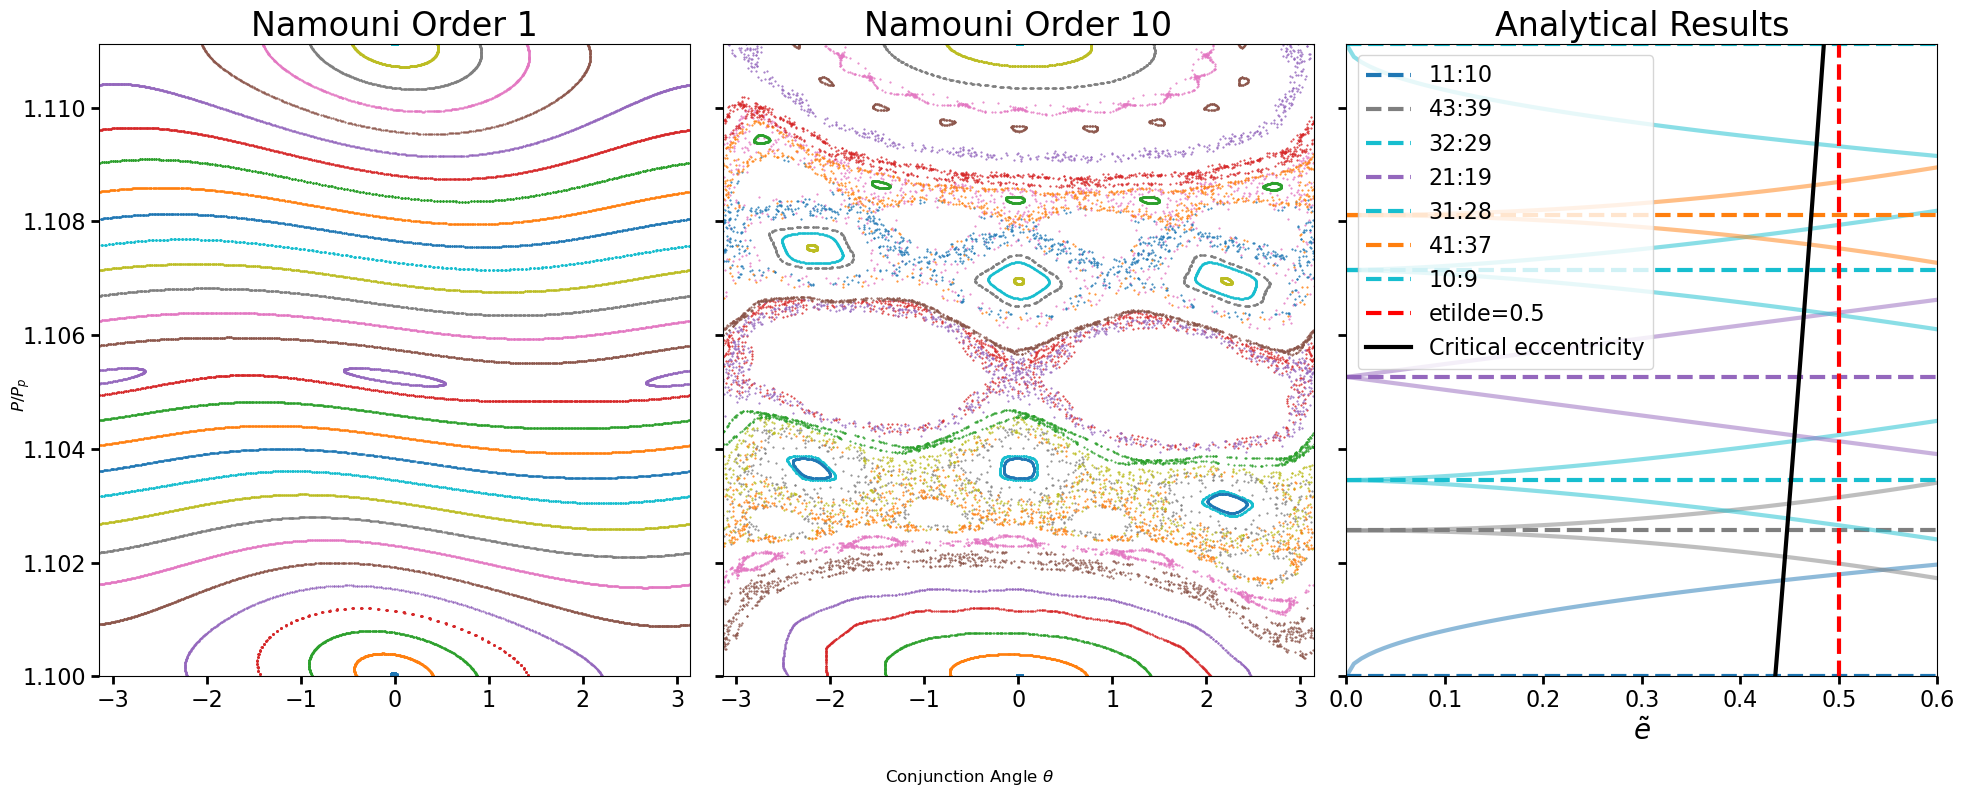

In [7]:
%%time
h = np.ones(11)
h[1] = 0.535
h[2] = 0.426
h[3] = 0.420
h[4] = 0.454
h[5] = 0.519
h[6] = 0.613
h[7] = 0.742
h[8] = 0.914
h[9] = 1.143
h[10] = 1.445

A = np.ones(11)
A[1] = 0.845
A[2] = 0.754
A[3] = 0.748
A[4] = 0.778
A[5] = 0.832
A[6] = 0.904
A[7] = 0.995
A[8] = 1.104
A[9] = 1.235
A[10] = 1.388


fig,(ax2,ax3,ax4) = plt.subplots(1,3,figsize=(20,8),sharey=True)
# fig,(ax2,ax4) = plt.subplots(1,2,figsize=(20,8))
# fig.suptitle(f"Normalized Eccentricity={(etilde):.2f}")
fig.supxlabel(r'$\text{Conjunction Angle }\theta$')
fig.supylabel(r"$P/P_{p}$")
ax2.set_xlim(-np.pi, np.pi)
ax2.set_ylim(np.min(P21s),np.max(P21s))
ax3.set_xlim(-np.pi, np.pi)
ax3.set_ylim(np.min(P21s),np.max(P21s))
# ax4.set_xlim(-np.pi, np.pi)
ax4.set_ylim(np.min(P21s),np.max(P21s))

ax2.plot(-theta_conj_all[0,:,:].T, P21_conj_all[0,:,:].T, '.', markersize=1,rasterized=True)
ax2.set_title('Namouni Order 1')
# ax.set_xlim(-np.pi, np.pi)

curves = ax3.plot(-theta_conj_all[-1,:,:].T, P21_conj_all[-1,:,:].T, '.', markersize=1,rasterized=True)
ax3.set_title('Namouni Order 10')
# print(curves)
colorset = np.array([curves[0].get_color(),curves[7].get_color(),curves[9].get_color(),curves[14].get_color(),curves[19].get_color(),curves[21].get_color(),curves[29].get_color()])


order = 10
etildemax = 0.6
ax4.set_xlim(0,etildemax)
# ar0_list = (1+x0_arr)*ar_res
etildes = np.linspace(0, etildemax, 80) #for a_r vs. e plot
critical_e_list = np.zeros(len(ar0_list))
critical_e_list = critical_etilde(m, a1, (1+ar0_list*epsilon))
jmax = 50
kmax = 5
# for k in range(1,kmax+1):
#     for j in range(2*k+1, jmax):
#         if not relativelyprime(j, k):
#             continue
#         # print(j, k)
#         P21 = j/(j-k) # P2/P1
#         alpha = P21**(-2/3)
#         eps = m/3*(1 + alpha**(1/6))
#         es = np.linspace(0, etildemax, 100)
#         if P21 >= np.min(P21s) and P21 <= np.max(P21s):
#             print(j,k)
#             #ax.text(P21-0.005, 0.48-0.02*k, '{0}:{1}'.format(j, j-k), fontsize=20)
#             dPs = j/(j-k)*2*np.sqrt(3)*h[k]**(1/2)*eps**(1/2)*etildes**(k/2)
#             ax4.plot(etildes,P21+dPs, 'k', alpha=0.5,rasterized=True)
#             ax4.plot(etildes,P21-dPs, 'k', alpha=0.5,rasterized=True)
# dParr = np.zeros((len(select_jklist),len(etildes)))

for i ,ratios in enumerate(select_jklist):
    j, k = ratios
    P21 = j/(j-k) # P2/P1
    alpha = P21**(-2/3)
    eps = m/3*(1 + alpha**(1/6))
        # if P21 > 1/P21s.max()-0.01 and P21 < 1/P21s.min()+0.01:
            #ax.text(P21-0.005, 0.48-0.02*k, '{0}:{1}'.format(j, j-k), fontsize=20)
    es = np.linspace(0, etildemax, 100)
    dPs = 3*A[k]*m**(1/2)*etildes**(k/2)
    line, = ax4.plot(etildes,P21+dPs, colorset[i], alpha=0.5,rasterized=True)
    ax4.plot(etildes,P21-dPs, color=colorset[i], alpha=0.5,rasterized=True)
    ax4.axhline(y = P21,color=colorset[i],linestyle='--',label=f"{j}:{j-k}",rasterized=True)


ax4.axvline(x=etilde, color='red',linestyle='--',label=f'etilde={etilde}',rasterized=True)
ax4.plot(critical_e_list, P21s, color='black',label='Critical eccentricity',rasterized=True)
ax4.set_xlabel(r"$\tilde{e}$")
ax4.set_title('Analytical Results')
ax4.set_xlim(0,etildemax)
# ax4.set_ylim(np.min(P21s),np.max(P21s))
ax4.legend()


fig.tight_layout()
fig.savefig(f'cateyeall_ord_1and10_etilde_hiecc.pdf')


In [8]:
J=10
a1 = 1
a2 = (J/(J-1))**(2/3)*a1
((a2-a1)/a1)**4*(np.log(10)/2.2)**3

3.2143460014737234e-05

In [9]:
42/38

1.105263157894737

In [10]:
41/37

1.1081081081081081

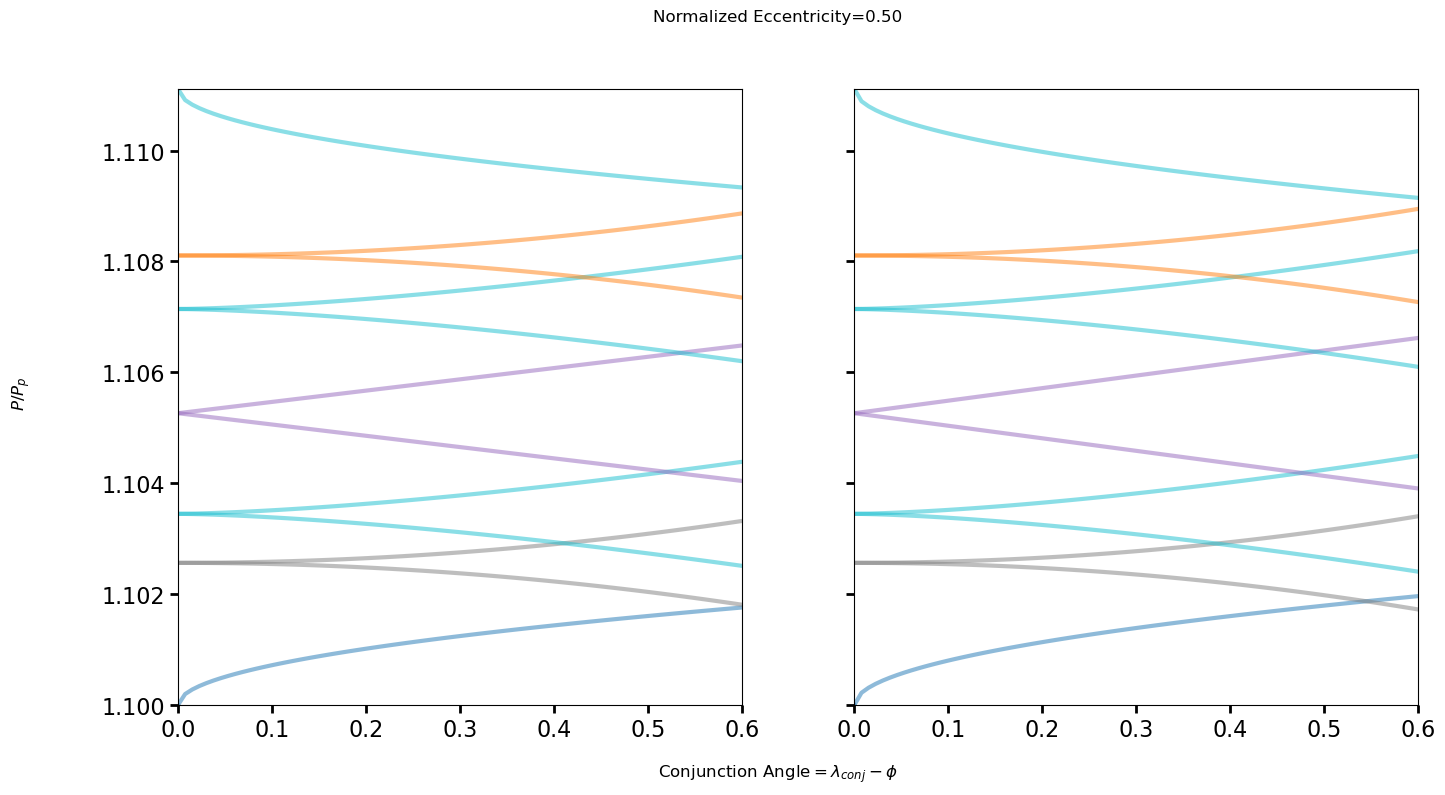

In [11]:
A = np.ones(11)
A[1] = 0.845
A[2] = 0.754
A[3] = 0.748
A[4] = 0.778
A[5] = 0.832
A[6] = 0.904
A[7] = 0.995
A[8] = 1.104
A[9] = 1.235
A[10] = 1.388


fig,(ax2,ax3) = plt.subplots(1,2,figsize=(16,8),sharey=True)
fig.suptitle(f"Normalized Eccentricity={(etilde):.2f}")
fig.supxlabel(r'$\text{Conjunction Angle}=\lambda_{conj}-\phi$')
fig.supylabel(r"$P/P_{p}$")
ax2.set_xlim(0,etildemax)
ax2.set_ylim(np.min(P21s),np.max(P21s))
ax3.set_xlim(0,etildemax)
ax3.set_ylim(np.min(P21s),np.max(P21s))

for i ,ratios in enumerate(select_jklist):
    j, k = ratios
    P21 = j/(j-k) # P2/P1
    alpha = P21**(-2/3)
    eps = m/3*(1 + alpha**(1/6))
        # if P21 > 1/P21s.max()-0.01 and P21 < 1/P21s.min()+0.01:
            #ax.text(P21-0.005, 0.48-0.02*k, '{0}:{1}'.format(j, j-k), fontsize=20)
    es = np.linspace(0, etildemax, 100)
    dPs = j/(j-k)*2*np.sqrt(3)*h[k]**(1/2)*eps**(1/2)*etildes**(k/2)
    line, = ax2.plot(etildes,P21+dPs, colorset[i], alpha=0.5,rasterized=True)
    ax2.plot(etildes,P21-dPs, color=colorset[i], alpha=0.5,rasterized=True)

for i ,ratios in enumerate(select_jklist):
    j, k = ratios
    P21 = j/(j-k) # P2/P1
    alpha = P21**(-2/3)
    eps = m/3*(1 + alpha**(1/6))
        # if P21 > 1/P21s.max()-0.01 and P21 < 1/P21s.min()+0.01:
            #ax.text(P21-0.005, 0.48-0.02*k, '{0}:{1}'.format(j, j-k), fontsize=20)
    es = np.linspace(0, etildemax, 100)
    dPs = 3*A[k]*m**(1/2)*etildes**(k/2)
    line, = ax3.plot(etildes,P21+dPs, colorset[i], alpha=0.5,rasterized=True)
    ax3.plot(etildes,P21-dPs, color=colorset[i], alpha=0.5,rasterized=True)